In [15]:
from adabmDCA.fasta import import_from_fasta, decode_sequence, write_fasta
from adabmDCA.sampling import gibbs_sampling
from adabmDCA.statmech import compute_energy
import adabmDCA as dca
from tqdm.notebook import tqdm

import numpy as np
import pandas as pd
import os
import matplotlib.pyplot as plt
import seaborn as sns
import time
import RNA
import torch

from concurrent.futures import ProcessPoolExecutor
from functools import partial

# use latex and font size 14
plt.rc('text', usetex=True)
plt.rc('font', size=16)

tokens = "ACGU-"
dot_bracket_with_pk = "...(((((((..((....)).)))))))...((((((....((((((...((...((((((....))))))..))...))))))(((...(.((((((....)))))).)..)))...[.[[[[[...))))))((((...(((....)))..))))......]]]]]]..((.(((((....))))).....)).."

In [2]:
def compute_bpp_matrix(sequence):
    """
    Compute the base-pairing probability (bpp) matrix via ViennaRNA.

    Parameters
    ----------
    sequence : str
        RNA sequence (T già convertiti in U se presenti gap).

    Returns
    -------
    bpp : np.ndarray, shape (L, L)
        Matrice simmetrica delle probabilità di appaiamento (L = len(sequence)).
    """
    fc = RNA.fold_compound(sequence)
    propensity, ensemble_energy = fc.pf()
    basepair_probs = fc.bpp()  # nested list, 1-based

    L = len(sequence)
    bpp = np.zeros((L, L), dtype=float)
    for i in range(1, L+1):
        for j in range(1, L+1):
            bpp[i-1, j-1] = basepair_probs[i][j]
    return bpp


def dot_bracket_to_ss_matrix(ss):
    """
    Convert a dot-bracket string into a binary contact matrix.

    Parameters
    ----------
    ss : str
        Notazione secondaria “dot-bracket”.

    Returns
    -------
    cm : np.ndarray, shape (L, L)
        Matrice binaria con cm[i,j]=1 se i e j sono appaiati nella struttura.
    """
    L = len(ss)
    cm = np.zeros((L, L), dtype=int)
    stack_round = []  # for (
    stack_square = []  # for [
    stack_angle = []  # for <
    stack_curly = []  # for {
    for pos, c in enumerate(ss):
        if c == '(':
            stack_round.append(pos)
        elif c == '[':
            stack_square.append(pos)
        elif c == '<':
            stack_angle.append(pos)
        elif c == '{':
            stack_curly.append(pos)
        elif c == ')':
            if stack_round:
                i = stack_round.pop()
                cm[i, pos] = cm[pos, i] = 1
        elif c == ']':
            if stack_square:
                i = stack_square.pop()
                cm[i, pos] = cm[pos, i] = 1
        elif c == '>':
            if stack_angle:
                i = stack_angle.pop()
                cm[i, pos] = cm[pos, i] = 1
        elif c == '}':
            if stack_curly:
                i = stack_curly.pop()
                cm[i, pos] = cm[pos, i] = 1
    return cm



def _bpp_score_for_sequence(seq, cm):
    seq = seq.upper().replace('T', 'U')
    bpp = compute_bpp_matrix(seq)
    return float((bpp * cm).sum())

def compute_bpp_scores(sequences_one_hot, dot_bracket, num_workers=4):
    sequences_v = torch.argmax(sequences_one_hot, dim=-1)
    sequences = ["GUG"+ "".join(tokens[i] for i in sequence) + "G" for sequence in sequences_v]

    """
    Compute BPP scores and gap violations for a list of sequences given a dot-bracket structure.

    Args:
        sequences (list of str): List of RNA sequences (strings with 'U' instead of 'T').
        dot_bracket (str): Dot-bracket string representing the structure.
        num_workers (int): Number of processes to parallelize over.

    Returns:
        bpp_scores (list of float): BPP scores for each sequence.
        gap_violations (int): Number of gap violations across all sequences.
    """
    # Convert dot-bracket to structure matrix once
    cm = dot_bracket_to_ss_matrix(dot_bracket)

    # Use process pool to parallelize computation
    with ProcessPoolExecutor(max_workers=num_workers) as executor:
        bpp_scores = list(executor.map(partial(_bpp_score_for_sequence, cm=cm), sequences))

    return bpp_scores

### Import DCA model

In [3]:
# Load model
path_model = "../Group_I_Intron/modello_FC_T=1"
params_np = np.load(path_model)
params = {
    'bias': torch.tensor(params_np['h_local'], dtype=torch.float32, device='cuda').contiguous(),
    'coupling_matrix': torch.tensor(params_np['couplings'], dtype=torch.float32, device='cuda').contiguous()
}

### Import data

In [4]:
path_wt = "../lore/WTs_to_thermo_fix.fasta"
wt_headers, wt_sequences_enc = import_from_fasta(path_wt, tokens=tokens)
wt_sequences_enc = wt_sequences_enc[:, 3:-1]
wt_sequences_oh = torch.nn.functional.one_hot(torch.tensor(wt_sequences_enc), num_classes=len(tokens)).float().to("cuda")
wt_mapping = {header: seq_oh for header, seq_oh in zip(wt_headers, wt_sequences_oh)}

fname_azo = "../Group_I_Intron/azo.seq"
h_azo, s_azo_enc = import_from_fasta(fname_azo, tokens=tokens)
s_azo_oh = torch.nn.functional.one_hot(torch.tensor(s_azo_enc), num_classes=len(tokens)).float().to("cuda")

In [5]:
fname_mapping_names = "../lore/WTs_to_thermo_fix_mapping_names.txt"
mapping_names = {}
with open(fname_mapping_names, 'r') as f:
    for line in f:
        parts = line.strip().split()
        if len(parts) == 2:
            mapping_names[parts[0]] = parts[1]
print(mapping_names)

{'dca_f_sequenza_682': 'wt_1', 'dca_f_sequenza_689': 'wt_2', 'dca_f_sequenza_698': 'wt_3', 'dca_f_sequenza_707': 'wt_4', 'dca_f_sequenza_739': 'wt_5', 'dca_f_sequenza_762': 'wt_6', 'dca_f_sequenza_794': 'wt_7', 'dca_f_sequenza_799': 'wt_8', 'old_dca_619_20_30': 'wt_9', 'old_dca_953_30_40': 'wt_10'}


In [6]:
# Import Vaitea sequences
fname_vaitea = "../lore/sequences_vaitea.txt"
lines_vaitea = np.loadtxt(fname_vaitea, dtype=str)
vaitea_wt_refs = lines_vaitea[:,0]
sequences_vaitea_str = lines_vaitea[:,-1]
sequences_vaitea_enc = dca.encode_sequence(sequences_vaitea_str, tokens=tokens)
sequences_vaitea_oh = torch.nn.functional.one_hot(torch.tensor(sequences_vaitea_enc), num_classes=len(tokens)).float().to("cuda")

In [7]:
mapping_names_inv = {v: k for k, v in mapping_names.items()}

In [105]:
wt_name = "wt_9"

strict_requirements = True
priority = "dca"

wt_energy = dca.compute_energy(wt_mapping[wt_name].unsqueeze(0), params).item()
wt_bpp_score = compute_bpp_scores(wt_mapping[wt_name].unsqueeze(0), dot_bracket_with_pk, num_workers=1)[0]

paths_mutants = {
    "lowDCA_lowSB": f"../Experiment_sequences/lowDCA_lowSB/{wt_name}_mutants_lowDCA_lowSB_beta1.25_sb-3.00.fasta",
    "lowDCA_highSB": f"../Experiment_sequences/lowDCA_highSB/{wt_name}_mut_lowDCA_highSB_beta1.5_sb2.0.fasta",
    "highDCA_highSB": f"../Experiment_sequences/highDCA_highSB/{wt_name}_mut_highDCA_highSB_beta0_sb3.5.fasta"
}

In [106]:
df_mutants = pd.DataFrame()
print(f"Wild-type: {wt_name}, DCA energy: {wt_energy:.4f}, BPP score: {wt_bpp_score:.4f}")
for condition, path in paths_mutants.items():
    print(f"Importing mutant sequences {condition}")
    mut_headers, mut_sequences_enc = import_from_fasta(path, tokens=tokens)
    n_initial = len(mut_headers)
    mut_headers, mut_sequences_enc = import_from_fasta(path, tokens=tokens, remove_duplicates=True)
    n_unique = len(mut_headers)
    print(f"---> Initial sequences: {n_initial}, unique sequences: {n_unique}")
    mut_sequences_str = decode_sequence(mut_sequences_enc, tokens)
    mut_sequences_oh = torch.nn.functional.one_hot(torch.tensor(mut_sequences_enc), num_classes=len(tokens)).float().to("cuda")
    mean_seqid, err_seqid = dca.get_seqid_stats(mut_sequences_oh)
    mean_distance = len(mut_sequences_oh[0]) - mean_seqid
    print(f"---> Mean distance between mutants: {mean_distance:.4f} ± {err_seqid:.4f}")
    mut_sequences_oh = torch.nn.functional.one_hot(torch.tensor(mut_sequences_enc), num_classes=len(tokens)).float().to("cuda")
    dca_energies = dca.compute_energy(mut_sequences_oh, params).cpu().numpy()
    bpp_scores = compute_bpp_scores(mut_sequences_oh, dot_bracket_with_pk, num_workers=20)
    distances_from_azo = mut_sequences_oh.shape[1] -dca.get_seqid(mut_sequences_oh, s_azo_oh.squeeze(0)).cpu().numpy()
    print(f"---> Min distance from Azo: {distances_from_azo.min()}, Max distance from Azo: {distances_from_azo.max()}")
    # check distance from wild type
    distances_from_wt = mut_sequences_oh.shape[1] -dca.get_seqid(mut_sequences_oh, wt_mapping[wt_name].squeeze(0)).cpu().numpy()
    print(f"---> Min distance from WT: {distances_from_wt.min()}, Max distance from WT: {distances_from_wt.max()}")
    
    df_temp = pd.DataFrame({
        "header": mut_headers,
        "region": condition,
        "dca_energy": dca_energies,
        "bpp_score": bpp_scores,
        "sequence": mut_sequences_str
    })
    df_mutants = pd.concat([df_mutants, df_temp], ignore_index=True)   
    
# take vaitea sequences
print("\nVAITEA SEQUENCES")
wt_old_name = mapping_names_inv[wt_name]
vaitea_indices = np.where(vaitea_wt_refs == wt_old_name)[0]
vaitea_sequences_oh = sequences_vaitea_oh[vaitea_indices]
n_initial_vaitea = len(vaitea_indices)
unique_vaitea_sequences_oh = torch.unique(vaitea_sequences_oh, dim=0)
n_unique_vaitea = unique_vaitea_sequences_oh.shape[0]
print(f"---> Initial Vaitea sequences: {n_initial_vaitea}, unique Vaitea sequences: {n_unique_vaitea}")
vaitea_sequences_str = decode_sequence(unique_vaitea_sequences_oh.cpu().numpy(), tokens)
mean_seqid_vaitea, err_seqid_vaitea = dca.get_seqid_stats(unique_vaitea_sequences_oh)
mean_distance_vaitea = len(unique_vaitea_sequences_oh[0]) - mean_seqid_vaitea
print(f"---> Mean distance between Vaitea sequences: {mean_distance_vaitea:.4f} ± {err_seqid_vaitea:.4f}")
vaitea_dca_energies = dca.compute_energy(unique_vaitea_sequences_oh, params).cpu().numpy()
vaitea_bpp_scores = compute_bpp_scores(unique_vaitea_sequences_oh, dot_bracket_with_pk, num_workers=10)
distances_from_azo_vaitea = unique_vaitea_sequences_oh.shape[1] -dca.get_seqid(unique_vaitea_sequences_oh, s_azo_oh.squeeze(0)).cpu().numpy()
print(f"---> Min distance from Azo: {distances_from_azo_vaitea.min()}, Max distance from Azo: {distances_from_azo_vaitea.max()}")
# check distance from wild type
distances_from_wt_vaitea = unique_vaitea_sequences_oh.shape[1] -dca.get_seqid(unique_vaitea_sequences_oh, wt_mapping[wt_name].squeeze(0)).cpu().numpy()
print(f"---> Min distance from WT: {distances_from_wt_vaitea.min()}, Max distance from WT: {distances_from_wt_vaitea.max()}")
headers_vaitea = [f"{wt_name}_mut_highDCA_highSB_v_{i}" for i in range(unique_vaitea_sequences_oh.shape[0])]


df_temp_vaitea = pd.DataFrame({
    "header": headers_vaitea,
    "region": "vaitea",
    "dca_energy": vaitea_dca_energies,
    "bpp_score": vaitea_bpp_scores,
    "sequence": vaitea_sequences_str
})

# Filter vaitea sequences
bpp_high = 33
dca_low = 110
limit_distance_azo = (25, 30)

if strict_requirements:
    mask1 = np.array(vaitea_bpp_scores) > bpp_high
    mask2 = np.array(vaitea_dca_energies) > dca_low
    mask3 = (distances_from_azo_vaitea >= limit_distance_azo[0]) & (distances_from_azo_vaitea <= limit_distance_azo[1])
    mask4 = (distances_from_wt_vaitea >= 5) & (distances_from_wt_vaitea <= 10)
    df_temp_vaitea = df_temp_vaitea[mask1 & mask2 & mask3 & mask4].reset_index(drop=True)
    
else:
    mask3 = (distances_from_azo_vaitea >= limit_distance_azo[0]) & (distances_from_azo_vaitea <= limit_distance_azo[1])
    mask4 = (distances_from_wt_vaitea >= 5) & (distances_from_wt_vaitea <= 10)
    df_temp_vaitea = df_temp_vaitea[mask3 & mask4].reset_index(drop=True)
    
    
print(f"Number of Vaitea sequences after filtering: {len(df_temp_vaitea)}")

df_mutants = pd.concat([df_mutants, df_temp_vaitea], ignore_index=True)

Wild-type: wt_9, DCA energy: 85.2178, BPP score: 21.9461
Importing mutant sequences lowDCA_lowSB
---> Initial sequences: 194, unique sequences: 194
---> Mean distance between mutants: 12.7268 ± 0.1592
---> Min distance from Azo: 25.0, Max distance from Azo: 30.0
---> Min distance from WT: 5.0, Max distance from WT: 10.0
Importing mutant sequences lowDCA_highSB
---> Initial sequences: 2223, unique sequences: 2072
---> Mean distance between mutants: 9.0396 ± 0.0554
---> Min distance from Azo: 25.0, Max distance from Azo: 30.0
---> Min distance from WT: 5.0, Max distance from WT: 10.0
Importing mutant sequences highDCA_highSB
---> Initial sequences: 50, unique sequences: 50
---> Mean distance between mutants: 13.1600 ± 0.3805
---> Min distance from Azo: 28.0, Max distance from Azo: 30.0
---> Min distance from WT: 5.0, Max distance from WT: 10.0

VAITEA SEQUENCES
---> Initial Vaitea sequences: 100, unique Vaitea sequences: 100
---> Mean distance between Vaitea sequences: 12.6000 ± 0.2270
-

In [107]:
# Check that bpp and energy constraints are satisfied
bpp_low = 10
bpp_high = 33
dca_high = wt_energy
dca_low = 110

for region in df_mutants["region"].unique():
    df_cond = df_mutants[df_mutants["region"] == region]
    if region == "lowDCA_highSB":
        assert (df_cond["bpp_score"] > bpp_high).all(), f"In {region} some sequences violate the high SB constraint"
        assert (df_cond["dca_energy"] < dca_high).all(), f"In {region} some sequences violate the low DCA energy constraint"
    elif region == "lowDCA_lowSB":
        assert (df_cond["bpp_score"] < bpp_low).all(), f"In {region} some sequences violate the low SB constraint"
        assert (df_cond["dca_energy"] < dca_high).all(), f"In {region} some sequences violate the low DCA energy constraint"
    elif region == "highDCA_highSB":
        assert (df_cond["bpp_score"] > bpp_high).all(), f"In {region} some sequences violate the high SB constraint"
        assert (df_cond["dca_energy"] > dca_low).all(), f"In {region} some sequences violate the high DCA energy constraint"
    elif region == "vaitea":
        assert (df_cond["bpp_score"] > bpp_high).all(), f"In {region} some sequences violate the high SB constraint"
        assert (df_cond["dca_energy"] >= dca_low).all(), f"In {region} some sequences violate the high DCA energy constraint"

AssertionError: In highDCA_highSB some sequences violate the high SB constraint

In [108]:
# filter mutants. Take 150 random sequences for lowDCA_highSB and 50 random for lowDCA_lowSB and highDCA_highSB
random_state = 42
df_filtered = pd.DataFrame()
for region in df_mutants["region"].unique():
    df_cond = df_mutants[df_mutants["region"] == region]
    if region == "lowDCA_highSB":
        n_extract = min(150, len(df_cond))
        df_cond = df_cond.sample(n=n_extract, random_state=random_state, replace=False)
    elif region == "lowDCA_lowSB":
        n_extract = min(50, len(df_cond))
        df_cond = df_cond.sample(n=n_extract, random_state=random_state, replace=False)
    elif region == "highDCA_highSB":
        n_extract = min(50, len(df_cond))
        df_cond = df_cond.sample(n=n_extract, random_state=random_state, replace=False)
    df_filtered = pd.concat([df_filtered, df_cond], ignore_index=True)

In [109]:
# in df_filtered, remove a number of highDCA_highSB sequences corresponding to the number of vaitea sequences.
# remove those with smallest DCA energy
if strict_requirements:
    n_remove = len(df_filtered[df_filtered["region"] == "vaitea"])
    df_highDCA_highSB = df_filtered[df_filtered["region"] == "highDCA_highSB"]
    if priority == "DCA":
        df_highDCA_highSB = df_highDCA_highSB.sort_values(by="dca_energy", ascending=True).reset_index(drop=True)
    elif priority == "bpp":
        df_highDCA_highSB = df_highDCA_highSB.sort_values(by="bpp_score", ascending=False).reset_index(drop=True)
    df_highDCA_highSB_to_keep = df_highDCA_highSB.iloc[n_remove:]
    df_filtered = df_filtered[df_filtered["region"] != "highDCA_highSB"]
    df_filtered = pd.concat([df_filtered, df_highDCA_highSB_to_keep], ignore_index=True)
# else, consider both vaitea and highDCA_highSB sequences as belonging to the same region. keep the 50 sequences with highest DCA energy
# and a bpp score > soft_bpp_high
else:
    soft_bpp_high = 25
    soft_dca_low = 110
    df_hh = df_filtered[(df_filtered["region"] == "vaitea") | (df_filtered["region"] == "highDCA_highSB")]
    df_filtered = df_filtered[(df_filtered["region"] != "vaitea") & (df_filtered["region"] != "highDCA_highSB")]
    if priority == "DCA":
        df_hh = df_hh.sort_values(by="dca_energy", ascending=False).reset_index(drop=True)
        df_hh = df_hh[df_hh["bpp_score"] > soft_bpp_high]
    elif priority == "bpp":
        df_hh = df_hh.sort_values(by="bpp_score", ascending=False).reset_index(drop=True)
        df_hh = df_hh[df_hh["dca_energy"] > soft_dca_low]
    
    df_hh = df_hh.head(50)
    df_filtered = pd.concat([df_filtered, df_hh], ignore_index=True)

In [110]:
if strict_requirements:
    # count the number of sequences with dca_energy > dca_low and bpp_score > bpp_high
    n_highDCA_highSB = len(df_filtered[((df_filtered["dca_energy"] > dca_low) & (df_filtered["bpp_score"] > bpp_high))])
    print(f"Number of sequences with high DCA energy and high SB: {n_highDCA_highSB}")
else:
    # count the number of sequences with dca_energy > dca_low and bpp_score > bpp_high
    n_highDCA_highSB = len(df_filtered[((df_filtered["dca_energy"] > soft_dca_low) & (df_filtered["bpp_score"] > soft_bpp_high))])
    print(f"Number of sequences with high DCA energy and high SB: {n_highDCA_highSB}")

Number of sequences with high DCA energy and high SB: 1


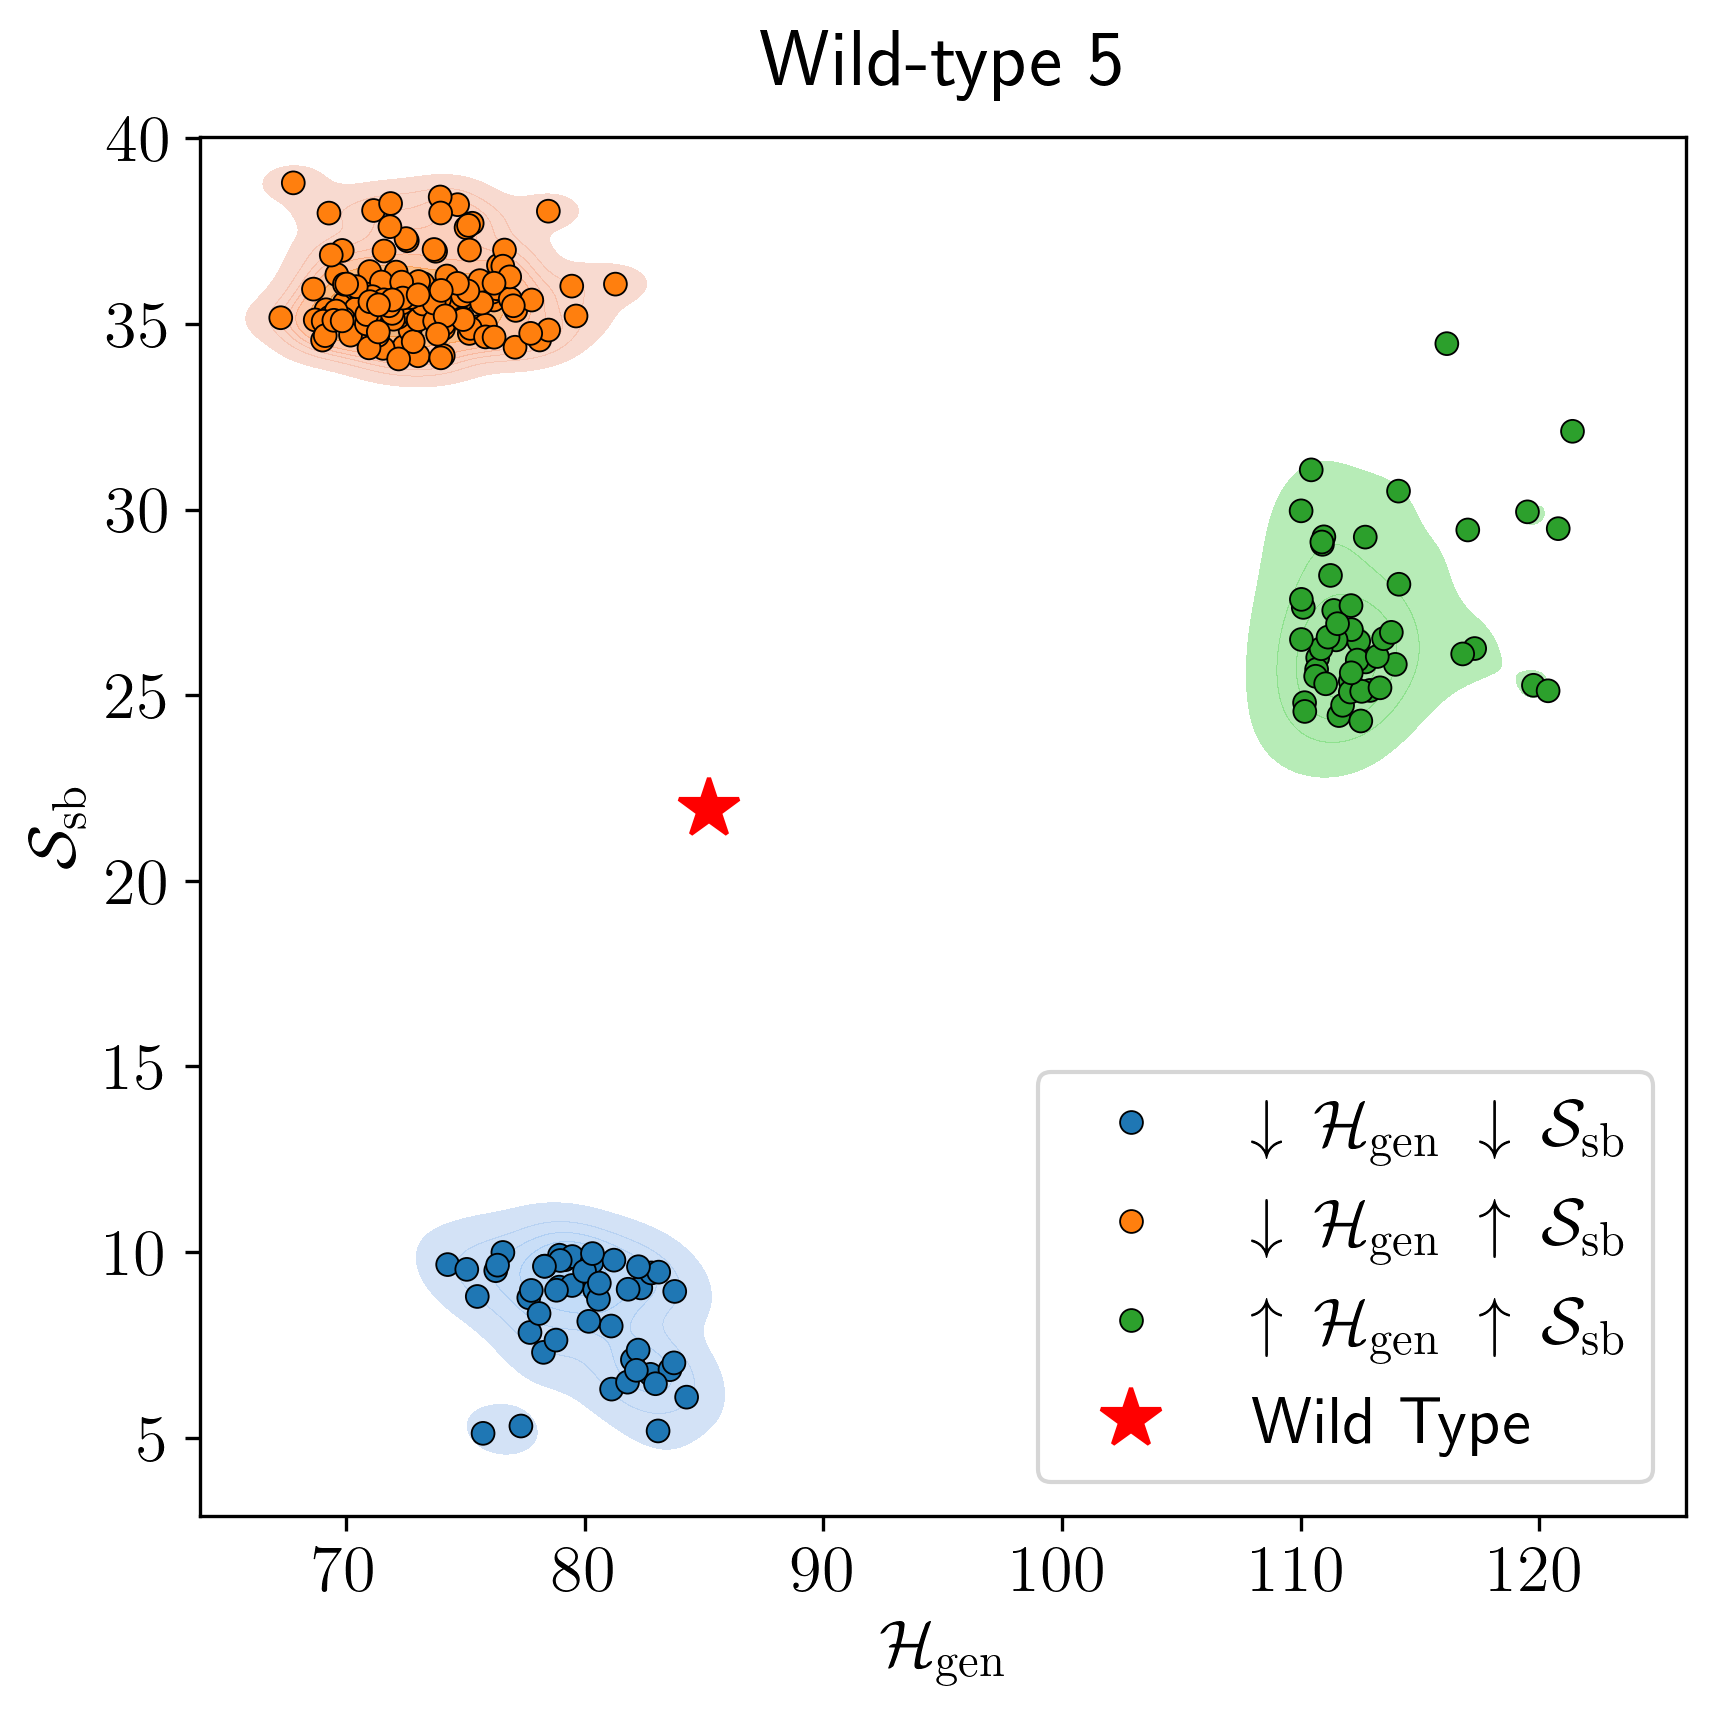

In [111]:
# create a new dataframe where the region entries are more descriptive
df_filtered_plot = df_filtered.copy()

# LaTeX legend labels (must be in math mode)
legend_map = {
    "lowDCA_lowSB": r"$\downarrow\,\mathcal{H}_{\mathrm{gen}}\;\downarrow\,\mathcal{S}_{\mathrm{sb}}$",
    "lowDCA_highSB": r"$\downarrow\,\mathcal{H}_{\mathrm{gen}}\;\uparrow\,\mathcal{S}_{\mathrm{sb}}$",
    "highDCA_highSB": r"$\uparrow\,\mathcal{H}_{\mathrm{gen}}\;\uparrow\,\mathcal{S}_{\mathrm{sb}}$",
    "vaitea": "Vaitea sequences"
}

# change the column name region to Region and apply legend labels
df_filtered_plot = df_filtered_plot.rename(columns={"region": "Region"})
df_filtered_plot["Region"] = df_filtered_plot["Region"].map(legend_map).fillna(df_filtered_plot["Region"])

# DCA energy vs BPP score with kde contours and custom legend labels
plt.figure(figsize=(6,6), dpi=300)
sns.kdeplot(data=df_filtered_plot, x="dca_energy", y="bpp_score", hue="Region", fill=True, alpha=0.5)
sns.scatterplot(data=df_filtered_plot, x="dca_energy", y="bpp_score", hue="Region", s=30, edgecolor='k', alpha=1.0)

# wild type point
plt.plot(wt_energy, wt_bpp_score, 'r*', markersize=15, label="Wild Type")

plt.title(f"Wild-type 5", y=1.02)
plt.xlabel(r"$\mathcal{H}_{\mathrm{gen}}$")
plt.ylabel(r"$\mathcal{S}_{\mathrm{sb}}$")
plt.legend()
plt.tight_layout()

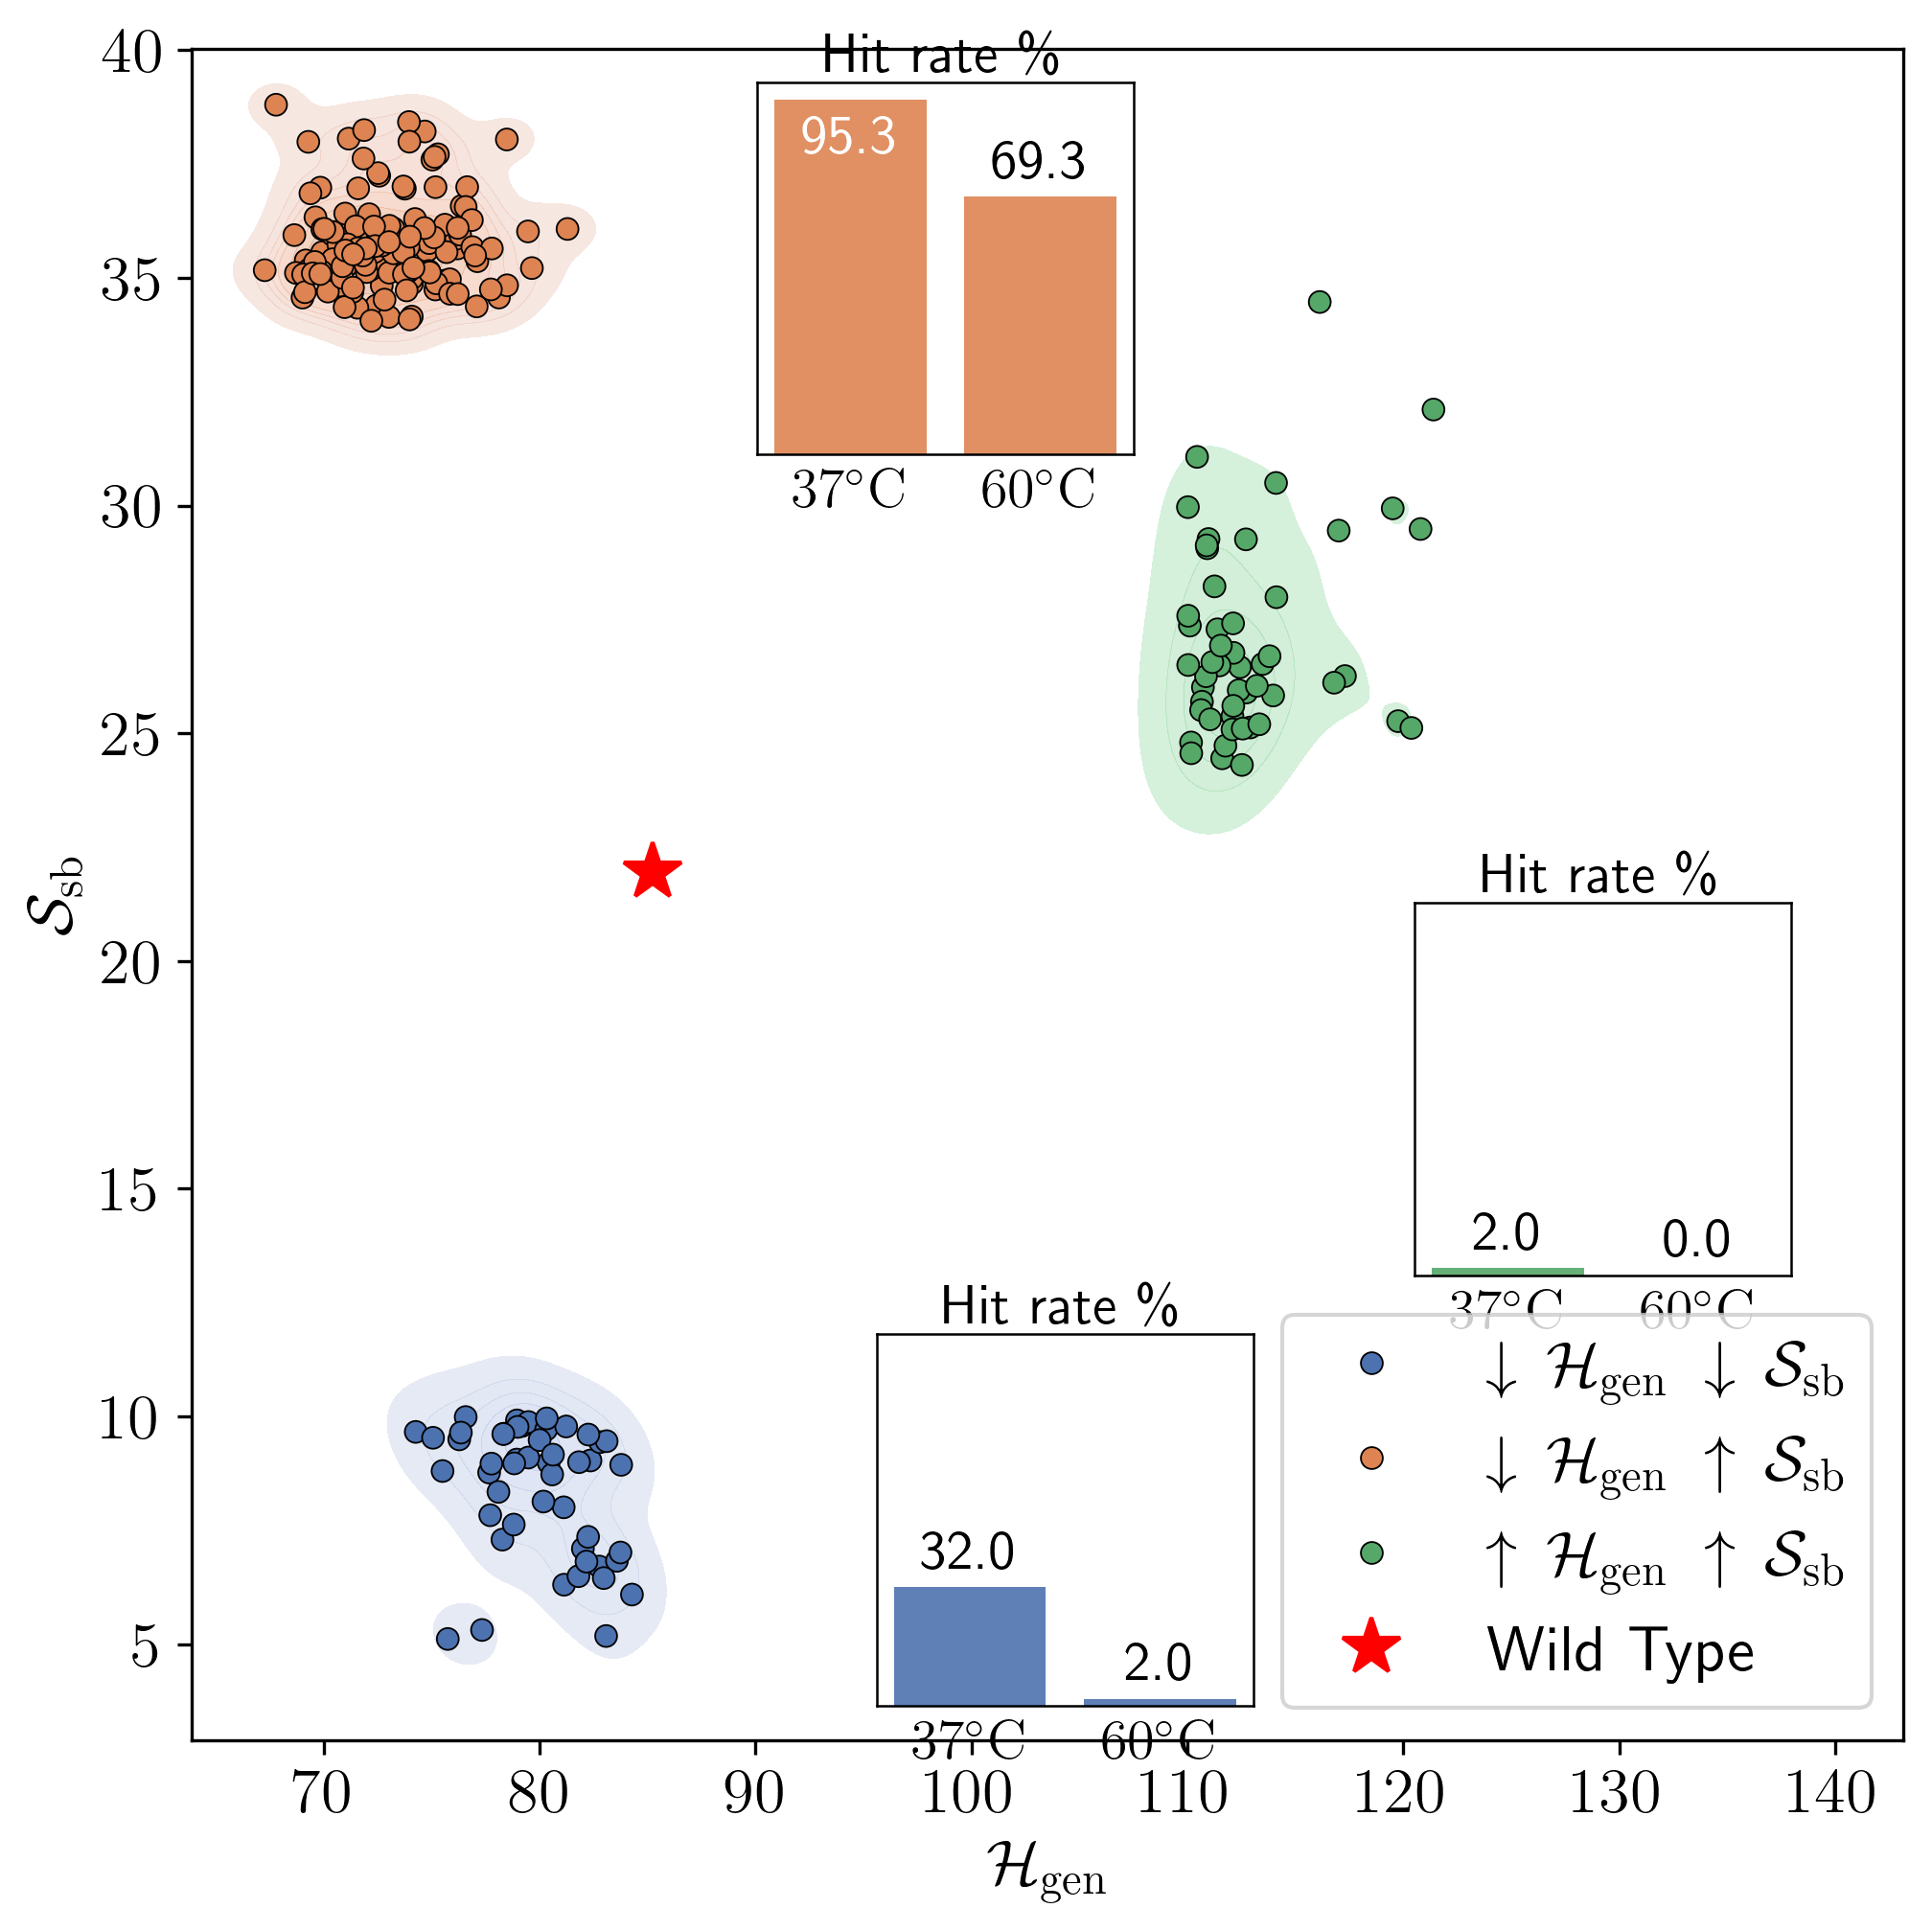

In [115]:
# create a new dataframe where the region entries are more descriptive
df_filtered_plot = df_filtered.copy()

# LaTeX legend labels (must be in math mode)
legend_map = {
    "lowDCA_lowSB": r"$\downarrow\,\mathcal{H}_{\mathrm{gen}}\;\downarrow\,\mathcal{S}_{\mathrm{sb}}$",
    "lowDCA_highSB": r"$\downarrow\,\mathcal{H}_{\mathrm{gen}}\;\uparrow\,\mathcal{S}_{\mathrm{sb}}$",
    "highDCA_highSB": r"$\uparrow\,\mathcal{H}_{\mathrm{gen}}\;\uparrow\,\mathcal{S}_{\mathrm{sb}}$",
}

hit_rates = {
    "lowDCA_lowSB": {
        r"$37^\circ\mathrm{C}$": 32.0,
        r"$60^\circ\mathrm{C}$": 2.0,
    },
    "lowDCA_highSB": {
        r"$37^\circ\mathrm{C}$": 95.3,
        r"$60^\circ\mathrm{C}$": 69.3,
    },
    "highDCA_highSB": {
        r"$37^\circ\mathrm{C}$": 2.0,
        r"$60^\circ\mathrm{C}$": 0.0,
    }
}

# keep only the regions that have hit-rate annotations
regions_for_plot = list(hit_rates.keys())
df_filtered_plot = df_filtered_plot[df_filtered_plot["region"].isin(regions_for_plot)].copy()
# df_filtered_plot["dca_energy"] = - df_filtered_plot["dca_energy"]

# keep original key for grouping + create legend label
df_filtered_plot["region_key"] = df_filtered_plot["region"]
df_filtered_plot["Region"] = df_filtered_plot["region"].map(legend_map)

# fixed palette so scatter/kde and inset bars share colors
region_labels = [legend_map[r] for r in regions_for_plot]
palette_colors = sns.color_palette("deep", n_colors=len(regions_for_plot))
palette = {lab: col for lab, col in zip(region_labels, palette_colors)}

fig, ax = plt.subplots(figsize=(7, 7), dpi=300)

# DCA energy vs BPP score with kde contours and custom legend labels
sns.kdeplot(
    data=df_filtered_plot,
    x="dca_energy",
    y="bpp_score",
    hue="Region",
    palette=palette,
    fill=True,
    alpha=0.35,
    ax=ax,
)
sns.scatterplot(
    data=df_filtered_plot,
    x="dca_energy",
    y="bpp_score",
    hue="Region",
    palette=palette,
    s=30,
    edgecolor='k',
    alpha=1.0,
    ax=ax,
)

# wild type point
ax.plot(wt_energy, wt_bpp_score, 'r*', markersize=15, label="Wild Type")

#ax.set_title(f"Wild-type 5", y=1.02)
ax.set_xlabel(r"$\mathcal{H}_{\mathrm{gen}}$")
ax.set_ylabel(r"$\mathcal{S}_{\mathrm{sb}}$")

# add inset bar charts near each region cluster
xmin, xmax = ax.get_xlim()
ymin, ymax = ax.get_ylim()

# tuned offsets (axes fraction) for cleaner placement
inset_offsets = {
    "lowDCA_lowSB": (0.25, -0.05),
    "lowDCA_highSB": (0.3, 0.02),
    #"highDCA_highSB": (0.05, -0.25),
    "highDCA_highSB": (0.05, -0.25),
}

for region_key in regions_for_plot:
    lab = legend_map[region_key]
    color = palette[lab]

    # center of region (median is robust)
    sub = df_filtered_plot[df_filtered_plot["region_key"] == region_key]
    cx = sub["dca_energy"].median()
    cy = sub["bpp_score"].median()

    # convert data coords -> axes fraction
    xfrac = (cx - xmin) / (xmax - xmin)
    yfrac = (cy - ymin) / (ymax - ymin)

    dx, dy = inset_offsets.get(region_key, (0.0, 0.0))
    w, h = 0.22, 0.22
    left = np.clip(xfrac + dx - w / 2, 0.04, 1.5)
    bottom = np.clip(yfrac + dy - h / 2, 0.02, 0.98 - h)

    iax = ax.inset_axes([left, bottom, w, h], transform=ax.transAxes)

    vals = [hit_rates[region_key][r"$37^\circ\mathrm{C}$"], hit_rates[region_key][r"$60^\circ\mathrm{C}$"]]
    bars = iax.bar([0, 1], vals, color=[color, color], alpha=0.9)
    iax.set_ylim(0, 100)
    iax.set_xticks([0, 1])
    iax.set_xticklabels([r"$37^\circ\mathrm{C}$", r"$60^\circ\mathrm{C}$"], fontsize=14)
    iax.set_yticks([])
    iax.set_title("Hit rate \%", fontsize=14, pad=1)
    iax.tick_params(length=0)

    # annotate bar heights: move label below if bar is too close to 100
    for bar, v in zip(bars, vals):
        if v >= 92:
            y_text = max(v - 4, 2)
            va_text = "top"
            text_color = "white"
        else:
            y_text = min(v + 2, 99)
            va_text = "bottom"
            text_color = "black"

        iax.text(
            bar.get_x() + bar.get_width() / 2,
            y_text,
            f"{v:.1f}",
            ha="center",
            va=va_text,
            fontsize=14,
            fontweight="bold",
            color=text_color,
        )

    for spine in iax.spines.values():
        spine.set_linewidth(0.6)

# deduplicate legend entries and keep WT
a_handles, a_labels = ax.get_legend_handles_labels()
unique = {}
for h, l in zip(a_handles, a_labels):
    if l not in unique:
        unique[l] = h
ax.legend(unique.values(), unique.keys(), loc="lower right", frameon=True)

ax.set_xlim(xmin, xmax + 17)
plt.tight_layout()
plt.show()

In [144]:
# create a df_final where the region of vaitea sequences is replaced with "highDCA_highSB"
df_final = df_filtered.copy()
df_final.loc[df_final["region"] == "vaitea", "region"] = "highDCA_highSB"

In [145]:
# Save results
output_dir = "../Experiment_sequences/selected_sequences"
df_final = df_final.reset_index(drop=True)
df_final.to_csv(os.path.join(output_dir, f"{wt_name}_mutants_selected.csv"), index=False)

### Extract control sequences for activity threshold

In [2]:
path_data = "../lore/paper_azo/summary_data.csv"
df = pd.read_csv(path_data)
df.head()

,model,header,distance_from_azo,activity,sequence,is_active
0,dca_sb,dca_sb_0_10_1_1_10,9,-0.464314,GUGCCUUGCGCCGGGAAACCGCGUAAGGGAUGGUGUCAAAUUCGGU...,True
1,dca_sb,dca_sb_0_10_2_1_10,9,-0.414826,GUGCCUUGCGCCGGGAAACCGCGUAAGGGAUGGUGUCAAAUUCGGU...,True
2,dca_sb,dca_sb_0_10_3_1_10,9,-0.268490,GUGCCUUGCGCCGGGAAACCGCGUAAGGGAUGGUGUCAAAUUCGGU...,True
3,dca_sb,dca_sb_0_10_4_1_10,9,-0.385578,GUGCCUUGCGCCGGGAAACCGCGUAAGGGAUGGUGUCAAAUUCGGU...,True
4,dca_sb,dca_sb_0_10_5_1_10,9,-0.580218,GUGCCUUGCACCGGGAAACCGUGUAAGGGAUGGUGUCAAAUUCGGU...,True


In [3]:
min_d_azo = 100

df_filtered = df[df["distance_from_azo"] >= min_d_azo]
print(f"Number of sequences with distance from Azo >= {min_d_azo}: {len(df_filtered)}")
print(f"Models available: {df_filtered['model'].unique()}")

Number of sequences with distance from Azo >= 100: 2777
Models available: ['sb' 'dca_sb']


In [4]:
df_control_seqs_old = df_filtered[df_filtered["activity"] >= -998]
df_control_seqs_integrate = df_filtered[df_filtered["activity"] == -999]

print(f"Number of control sequences (old assay): {len(df_control_seqs_old)}")
print(f"Number of control sequences (integrated assay): {len(df_control_seqs_integrate)}")

Number of control sequences (old assay): 543
Number of control sequences (integrated assay): 2234


In [5]:
num_extract = 1000 - len(df_control_seqs_old)
# extract random sequences from df_controlled_seqs_integrate
df_random_extract = df_control_seqs_integrate.sample(n=num_extract, random_state=42, replace=False)

df_control_final = pd.concat([df_control_seqs_old, df_random_extract], ignore_index=True)
print(f"Total number of control sequences after extraction: {len(df_control_final)}")
df_control_final.head()

Total number of control sequences after extraction: 1000


,model,header,distance_from_azo,activity,sequence,is_active
0,sb,sb_2522_100_110,108,-4.110692,GUGUGCGAUGACGAAAUUUCACAUCGUAAAAUCUAUCCACACCAGU...,False
1,sb,sb_2524_100_110,101,-4.430748,GUGUGCCAUGACGAGUUUUCACAUGGUAAAAGCUAUCCACACCAGU...,False
2,sb,sb_2525_100_110,109,-5.084723,GUGUGCGGUGACGAAAUUUCACACCGUAAAAUCUAUCCACACCCCU...,False
3,sb,sb_2526_100_110,107,-4.626413,GUGUGCGGUGACGAAAUUUCACACCGUAAAAUCUAUCCACACCACU...,False
4,sb,sb_2527_100_110,108,-4.933271,GUGUGCGAUGACGAAUUUUCACAUCGUAAAAUCUAUCCACACCAGU...,False


In [6]:
df_control_final.to_csv("../Experiment_sequences/Control_sequences.csv", index=False)

In [7]:
# save also as fasta
write_fasta("../Experiment_sequences/Control_sequences.fasta", df_control_final["header"].tolist(), df_control_final["sequence"].tolist())